# Arabica–chicory: reflectance training samples (raw scans → patch spectra)

The same first stage that was run on the robusta blends (`reflectance_training_samples (1).ipynb` for
sessions 1–2 and `reflectance_training_samples_batch3.ipynb` for session 3), now on the arabica scans in
`RIYAN HDD/arabica/`. The settings are identical, so the arabica patches can be compared with the robusta
ones and go through the same modelling notebook later.

| Step | Robusta notebooks | This notebook |
|---|---|---|
| Input | radiance cubes (`*_raw_rad_float32.img`) exported by the HySpex software | **raw camera counts** (`*_raw.hyspex`) |
| Dark signal | already removed by the HySpex software | **subtracted here**, using the background frame (mean of 200 dark frames) the camera stores in each file's header |
| White reference | per across-track column, Spectralon certificate | same |
| White strip and dishes | drawn by hand in an OpenCV window | **found automatically** (ring-shaped template on the dish rim). The hand-drawing window is still here if a shape needs fixing |
| Dish mask | 4 px erosion, dark < 55 % of median, glare > 99.7th percentile | same |
| Patches | 12 × 12 px, ≥ 92 % valid, ≤ 150 per dish, seed 0 | same |
| Output | `training_samples.csv`, one row per patch | same columns, plus a file with the session-1 anchors added |

**Why raw counts work just as well.** Reflectance is a ratio: sample signal ÷ white-strip signal in the same
column and band. Radiance is raw counts minus the dark signal, times a calibration factor for that pixel.
The factor is the same on top and bottom of the ratio and cancels. Only the dark signal has to be removed.
Section 3 checks this on a strip that appears in both an arabica scan and a robusta scan from the same
day.

**Sessions.** The arabica blends were scanned on the same days as the robusta blends, so the session
numbers match: session 2 = 4 Sep (50–10 % chicory), session 3 = 8 Sep (45–5 % chicory). Session 1
(1 Sep) has no new scans. Its pure arabica (AB100, 0 % chicory) and pure chicory (CH100) dishes were
already extracted in `samples_out/`, and section 9 adds them as the 0 % anchor, the same role RB100 has
for robusta.

**Outputs:** `arabica_out/`.

## 1. Configuration

In [1]:
import os, re, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Rectangle
from scipy import ndimage, signal
import cv2

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": "white"})

# ------------------------------------ EDIT ------------------------------------
BASE      = Path(os.environ.get("COFFEE_DATA", "."))
DATA_DIR  = Path(os.environ.get("COFFEE_RAW", "/run/media/riyanvarghese/RIYAN HDD")) / "arabica"          # the raw arabica scans
PANEL_TXT = BASE / "SRT-MS-050__1_.txt"
OUT       = BASE / "arabica_out"
S1_CSV    = BASE / "samples_out" / "training_samples.csv"               # AB100 + CH100 from 1 Sep
CHECK_RAD = BASE / "stir1_SWIR_384_SN3189_9000us_2026-09-04T161044_raw_rad_float32.img"  # robusta, same day

# Dishes in order FROM THE WHITE STRIP (top of the scan) downwards, as in the robusta sessions:
# the dish nearest the strip has the most chicory. Label = AB[arabica % : chicory %].
# !! ASSUMED from the robusta layout of the same days; section 10 checks the direction with the spectra.
#    If a dish order is different, change these two lists and re-run everything.
DAY2_PLATES = ["AB[50:50]", "AB[60:40]", "AB[70:30]", "AB[80:20]", "AB[90:10]"]   # 4 Sep
DAY3_PLATES = ["AB[55:45]", "AB[65:35]", "AB[75:25]", "AB[85:15]", "AB[95:5]"]    # 8 Sep
DAY_RULES   = [("2026-09-04", 2, DAY2_PLATES), ("2026-09-08", 3, DAY3_PLATES)]

# Keep these identical to the robusta extraction, or the samples will not be comparable.
ROUND_WL   = 0      # decimals on the wavelength column names: 0 -> 952, 958, 963 ...
PATCH      = 12     # patch side in pixels
STRIDE     = 12     # == PATCH means non-overlapping
MIN_VALID  = 0.92   # a patch is kept only if this fraction of its pixels are inside the mask
MAX_PER_PLATE = 150 # cap; patches beyond this are randomly subsampled
ERODE_PX   = 4      # trimmed inward from the dish shape
MM_PER_PX  = 0.73   # header nominal, used only to report patch size in mm
SEED = 0

# automatic shapes: dish shape = detected rim circle shrunk by this many pixels,
# white rectangle = detected bright strip shrunk by this many rows top and bottom
DISH_INSET_PX  = 6
STRIP_INSET_PX = 8
EDIT_BY_HAND   = False   # True opens the OpenCV drawing window (section 4b) to adjust shapes
# -------------------------------------------------------------------------------

OUT.mkdir(exist_ok=True, parents=True)
ROI_FILE = OUT / "rois.json"
RNG = np.random.default_rng(SEED)
print("data dir exists:", DATA_DIR.exists(), "| output:", OUT)

data dir exists: True | output: /run/media/riyanvarghese/RIYAN HDD/coffee data/arabica_out


## 2. Reading the raw HySpex scans

Each `.hyspex` file is a 2.6 MB binary header followed by the image (unsigned 16-bit counts, band-interleaved
by line). The header holds, in order: the 288 band wavelengths, a spectral response vector, a 288 × 384
response matrix, and the **background**: the mean of the 200 dark frames the camera records before each
scan, per band and across-track column. The reader finds the wavelength list in the header and reads the
background that follows, then subtracts it from every frame it returns. Saturated pixels (65535) become
missing values.

In [2]:
ENVI_DTYPES = {1:"u1", 2:"i2", 3:"i4", 4:"f4", 5:"f8", 12:"u2", 13:"u4"}

def parse_envi_header(p):
    txt = Path(p).read_text(errors="ignore").replace("\r", "")
    body = txt.split("\n", 1)[1] if "\n" in txt else ""
    out, pos = {}, 0
    pat = re.compile(r"^\s*([\w\s]+?)\s*=\s*(\{.*?\}|[^\n]*)", re.S | re.M)
    while pos < len(body):
        m = pat.search(body, pos)
        if not m: break
        k, v = m.group(1).strip().lower(), m.group(2).strip()
        if v.startswith("{") and not v.endswith("}"):
            e = body.find("}", m.end(2)); v = body[m.start(2):e+1]; pos = e + 1
        else: pos = m.end(2)
        out[k] = v
    for k in ["samples","lines","bands","header offset","data type","byte order"]:
        if k in out: out[k] = int(float(out[k]))
    if "data ignore value" in out: out["data ignore value"] = float(out["data ignore value"])
    if "wavelength" in out:
        out["wavelength"] = np.array([float(x) for x in
            out["wavelength"].strip("{}").replace("\n"," ").split(",") if x.strip()])
    out["interleave"] = out.get("interleave","bsq").strip().lower()
    return out


def hyspex_background(path, header_bytes, wl, S):
    # Locate the wavelength list (packed float64, not 8-byte aligned) in the binary header.
    # Layout after it: response vector (B), response matrix (B x S), background (B x S).
    raw = Path(path).open("rb").read(header_bytes)
    B = wl.size
    for off in range(0, min(len(raw) - 16, 20000)):
        a, b = np.frombuffer(raw, "<f8", count=2, offset=off)
        if abs(a - wl[0]) < 1e-3 and abs(b - wl[1]) < 1e-3:
            break
    else:
        raise ValueError(f"{Path(path).name}: wavelength table not found in the header")
    hw = np.frombuffer(raw, "<f8", count=B, offset=off)
    assert np.allclose(hw, wl, atol=1e-3), "header wavelengths do not match the .hdr"
    bg_off = off + 2 * B * 8 + B * S * 8
    bg = np.frombuffer(raw, "<f8", count=B * S, offset=bg_off).reshape(B, S)
    assert 100 < np.median(bg) < 60000, f"implausible background level {np.median(bg):.0f}"
    return bg.T.astype(np.float32), bg_off          # (columns, bands)


class Cube:
    def __init__(self, hdr):
        self.hdr_path = Path(hdr); self.h = parse_envi_header(hdr)
        stem = self.hdr_path.with_suffix("")
        self.path = next((c for e in (".hyspex", ".img", ".raw", ".dat", ".bin", "")
                          if (c := stem.with_suffix(e)).exists() and c != self.hdr_path), None)
        if self.path is None: raise FileNotFoundError(f"no data file beside {self.hdr_path.name}")
        L, S, B = self.h["lines"], self.h["samples"], self.h["bands"]
        dtc = ENVI_DTYPES[self.h["data type"]]
        nb = L*S*B*np.dtype(dtc).itemsize; fs = self.path.stat().st_size
        dec = self.h.get("header offset", 0)
        if fs == dec + nb: off, why = dec, "declared offset matches"
        elif fs == nb:     off, why = 0, "no offset"
        else: raise ValueError(f"{self.path.name}: size {fs} vs {nb}+{dec}; file may be truncated")
        self.offset, self.offset_reason = off, why
        dt = np.dtype(dtc).newbyteorder("<" if self.h.get("byte order",0)==0 else ">")
        shp = {"bil":(L,B,S),"bsq":(B,L,S),"bip":(L,S,B)}[self.h["interleave"]]
        mm = np.memmap(self.path, dtype=dt, mode="r", offset=off, shape=shp)
        self.arr = {"bil":mm.transpose(0,2,1),"bsq":mm.transpose(1,2,0),"bip":mm}[self.h["interleave"]]
        self.wl = self.h["wavelength"]; self.ignore = self.h.get("data ignore value", None)
        self.is_raw = np.dtype(dtc).kind == "u"; self._br = {}
        self.bg, self.bg_offset = (hyspex_background(self.path, off, self.wl, S) if self.is_raw
                                   else (np.zeros((S, B), np.float32), None))

    @property
    def shape(self): return self.arr.shape

    def region(self, r0, r1, c0=0, c1=None):
        # dark-subtracted signal, (rows, columns, bands)
        c1 = self.shape[1] if c1 is None else c1
        b = np.array(self.arr[r0:r1, c0:c1, :], dtype=np.float32)
        if self.ignore is not None: b[b == self.ignore] = np.nan
        return b - self.bg[None, c0:c1, :]

    def brightness(self, step=1, lo=1500, hi=1700):
        # mean of 8 bands near 1500-1700 nm, background removed (cached: it is used several times)
        ck = (step, lo, hi)
        if ck in self._br: return self._br[ck]
        idx = [i for i, w in enumerate(self.wl) if lo <= w <= hi][:8]
        s = np.array(self.arr[::step, ::step, :][:, :, idx], dtype=np.float32)
        if self.ignore is not None: s[s == self.ignore] = np.nan
        self._br[ck] = np.nanmean(s - self.bg[None, ::step, idx], axis=2)
        return self._br[ck]


def load_white_cert(txt_path, wl):
    rows = []
    for line in Path(txt_path).read_text(errors="ignore").replace("\r","").split("\n"):
        p = line.strip().split("\t")
        if len(p) >= 2:
            try: rows.append([float(x) for x in p[:5]])
            except ValueError: continue
    a = np.array(rows)
    return np.interp(wl, a[:,0], a[:,1]), (wl < a[0,0]) | (wl > a[-1,0])


def capture_of(stem):
    m = re.search(r"stir\s*(\d+)", stem, re.I)       # stir1 / batch2stir1 -> 1
    return int(m.group(1)) if m else None

CUBES, INFO = {}, {}
for h in sorted(DATA_DIR.glob("*.hdr")):
    c = Cube(h); CUBES[h.stem] = c
    day, plates = next(((d, pl) for s, d, pl in DAY_RULES if s in h.stem), (None, []))
    INFO[h.stem] = dict(day=day, capture=capture_of(h.stem), plates=plates)
    print(f"  {h.stem}\n     {c.shape[0]}x{c.shape[1]}x{c.shape[2]} | {c.offset_reason} | "
          f"background {np.median(c.bg):.0f} counts (header byte {c.bg_offset}) | "
          f"session {day}, stir {INFO[h.stem]['capture']}, {len(plates)} dishes")
assert all(v["day"] is not None for v in INFO.values()), "a scan matched no DAY_RULES entry"

k0 = list(CUBES)[0]
WL = CUBES[k0].wl.copy()
R_WHITE, OUTSIDE = load_white_cert(PANEL_TXT, WL)
WL_R = np.round(WL, ROUND_WL)
if ROUND_WL == 0: WL_R = WL_R.astype(int)
assert len(set(WL_R.tolist())) == WL.size
print(f"\n{WL.size} bands {WL[0]:.1f}-{WL[-1]:.1f} nm | white certificate {R_WHITE[0]:.4f} -> {R_WHITE[-1]:.4f}")

  batch2stir1_SWIR_384_SN3189_9000us_2026-09-08T121345_raw
     1750x384x288 | declared offset matches | background 9706 counts (header byte 891525) | session 3, stir 1, 5 dishes
  batch2stir2_SWIR_384_SN3189_9000us_2026-09-08T122149_raw
     1750x384x288 | declared offset matches | background 9881 counts (header byte 891525) | session 3, stir 2, 5 dishes
  batch2stir3_SWIR_384_SN3189_9000us_2026-09-08T123001_raw
     1750x384x288 | declared offset matches | background 10010 counts (header byte 891525) | session 3, stir 3, 5 dishes
  stir1_SWIR_384_SN3189_9000us_2026-09-04T151627_raw
     1700x384x288 | declared offset matches | background 10449 counts (header byte 891525) | session 2, stir 1, 5 dishes
  stir2_SWIR_384_SN3189_9000us_2026-09-04T152723_raw
     1700x384x288 | declared offset matches | background 10521 counts (header byte 891525) | session 2, stir 2, 5 dishes
  stir3_SWIR_384_SN3189_9000us_2026-09-04T153811_raw
     1700x384x288 | declared offset matches | background 1058

## 3. Check: raw counts minus background give the same reflectance as the HySpex radiance

The grey strip above the white reference is the same object in every scan. On 4 Sep it was scanned in an
arabica scan (raw counts, 15:16) and a robusta scan (radiance from the HySpex software, 16:10). Its
reflectance (grey ÷ white, per column) is computed both ways. If the background subtraction is right, the
two agree; without it, they do not.

arabica scan, raw minus background            ÷ radiance-based: median 0.9989  (1-99 %: 0.9970-0.9997)
arabica scan, raw (no background removed)     ÷ radiance-based: median 1.2290  (1-99 %: 1.1874-1.3379)


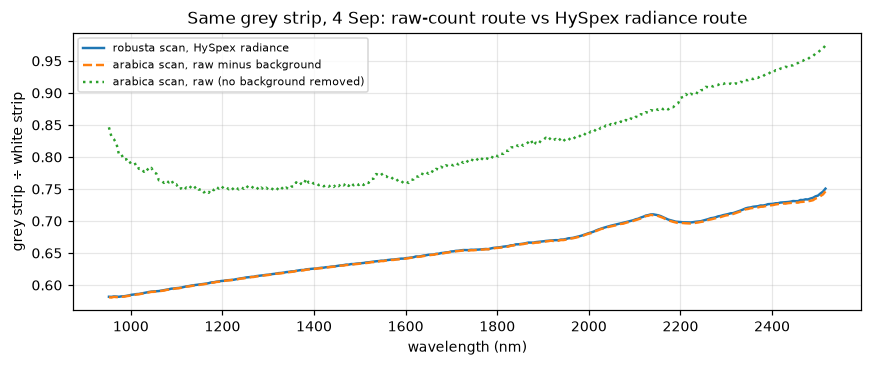

In [3]:
def strip_ratio(arr_rows, sub):
    # median over rows, then per-column ratio grey / white, median over the central columns
    W = np.median(arr_rows["white"] - sub, axis=0)
    G = np.median(arr_rows["grey"] - sub, axis=0)
    ok = W > (50 if np.nanmax(W) > 100 else 0)
    r = np.where(ok, G / np.where(ok, W, 1), np.nan)
    return np.nanmedian(r[20:364], axis=0)

ark = next(k for k in CUBES if "2026-09-04" in k and INFO[k]["capture"] == 1)
ac = CUBES[ark]
grab = lambda arr: {"white": np.array(arr[140:240], np.float64), "grey": np.array(arr[20:100], np.float64)}
a_rows = grab(ac.arr)
check = {"arabica scan, raw minus background": strip_ratio(a_rows, ac.bg.astype(np.float64)),
         "arabica scan, raw (no background removed)": strip_ratio(a_rows, 0.0)}
if CHECK_RAD.exists():
    rc = Cube(CHECK_RAD.with_suffix(".hdr"))
    check = {"robusta scan, HySpex radiance": strip_ratio(grab(rc.arr), 0.0), **check}
    ref = check["robusta scan, HySpex radiance"]
    band = (WL >= 1000) & (WL <= 2450)
    for k, v in check.items():
        if k.startswith("arabica"):
            q = v[band] / ref[band]
            print(f"{k:45s} ÷ radiance-based: median {np.median(q):.4f}  (1-99 %: {np.percentile(q,1):.4f}-{np.percentile(q,99):.4f})")
else:
    print("robusta radiance scan not found; check skipped")

fig, ax = plt.subplots(figsize=(8, 3.4))
for (k, v), ls in zip(check.items(), ["-", "--", ":"]):
    ax.plot(WL, v, ls, lw=1.6, label=k)
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("grey strip ÷ white strip"); ax.grid(alpha=.3)
ax.set_title("Same grey strip, 4 Sep: raw-count route vs HySpex radiance route")
ax.legend(fontsize=7); plt.tight_layout()
plt.savefig(OUT / "check_raw_vs_radiance.png", dpi=130, bbox_inches="tight"); plt.show()

## 4. Composition labels

In [4]:
def parse_label(lab):
    if lab == "CH100":  return dict(species="chicory", arabica_pct=0.0,   chicory_pct=100.0, unknown=False)
    if lab == "AB100":  return dict(species="arabica", arabica_pct=100.0, chicory_pct=0.0,   unknown=False)
    m = re.match(r"AB\[(\d+):(\d+)\]", lab)
    if m:
        ab, ch = float(m.group(1)), float(m.group(2))
        assert ab + ch == 100, lab
        return dict(species="arabica_chicory", arabica_pct=ab, chicory_pct=ch, unknown=False)
    return dict(species="unknown", arabica_pct=np.nan, chicory_pct=np.nan, unknown=True)

print(pd.DataFrame([dict(session=d, position_from_strip=i + 1, label=l, **parse_label(l))
                    for _, d, pl in DAY_RULES for i, l in enumerate(pl)]).to_string(index=False))

 session  position_from_strip     label         species  arabica_pct  chicory_pct  unknown
       2                    1 AB[50:50] arabica_chicory         50.0         50.0    False
       2                    2 AB[60:40] arabica_chicory         60.0         40.0    False
       2                    3 AB[70:30] arabica_chicory         70.0         30.0    False
       2                    4 AB[80:20] arabica_chicory         80.0         20.0    False
       2                    5 AB[90:10] arabica_chicory         90.0         10.0    False
       3                    1 AB[55:45] arabica_chicory         55.0         45.0    False
       3                    2 AB[65:35] arabica_chicory         65.0         35.0    False
       3                    3 AB[75:25] arabica_chicory         75.0         25.0    False
       3                    4 AB[85:15] arabica_chicory         85.0         15.0    False
       3                    5  AB[95:5] arabica_chicory         95.0          5.0    False

## 5. White strip and dishes

**Automatic shapes.** The white strip is the longest run of bright rows in the top 450 rows; the rectangle
spans the full swath width and stops `STRIP_INSET_PX` rows short of each edge, so the grey strip above and
the shadow line below stay out. Each dish is found by its dark rim: a template that is bright inside a
circle and dark in a ring around it is slid over the image at radii 88–115 px, and the five strongest,
well-separated matches are the dishes, numbered from the strip downwards. The dish shape is that circle
shrunk by `DISH_INSET_PX`, which matches the size of the robusta ovals drawn by hand (about 100 px). The
mask cleaning in section 6 then removes any rim, shadow or glare that is still inside.

The shapes are saved in `rois.json` in the same format as the robusta `rois.json`, so the hand-drawing
window can open and adjust them (section 5b).

In [5]:
def find_strip(br):
    prof = np.nanmedian(br[:, 20:min(364, br.shape[1])], axis=1); top = prof[:450]
    thr = 0.5 * (np.percentile(top, 95) + np.percentile(top, 40)); hi = top > thr
    lab, n = ndimage.label(hi); k = np.argmax(ndimage.sum(hi, lab, range(1, n + 1))) + 1
    rows = np.where(lab == k)[0]
    return int(rows.min()), int(rows.max())

def ring_kernel(r_in, r_rim0, r_rim1):
    R = r_rim1 + 1; y, x = np.mgrid[-R:R + 1, -R:R + 1]; d = np.hypot(x, y)
    k = np.zeros_like(d); a = d <= r_in; b = (d >= r_rim0) & (d <= r_rim1)
    k[a] = 1 / a.sum(); k[b] = -1 / b.sum(); return k

def find_dishes(br, below, n, radii=range(88, 116, 3), min_sep=230):
    img = np.nan_to_num(br.astype(np.float64)); img = img / np.percentile(img[below:], 99)
    img[:below] = np.median(img[below:])
    best = rbest = None
    for r in radii:
        resp = signal.fftconvolve(img, ring_kernel(r - 8, r + 2, r + 12), mode="same")
        if best is None: best, rbest = resp, np.full(resp.shape, r)
        else:
            m = resp > best; best = np.where(m, resp, best); rbest = np.where(m, r, rbest)
    resp = best.copy(); resp[:below + 60] = -np.inf
    yy, xx = np.ogrid[:resp.shape[0], :resp.shape[1]]
    out = []
    for _ in range(n):
        cy, cx = np.unravel_index(np.argmax(resp), resp.shape)
        out.append(dict(cx=float(cx), cy=float(cy), r=int(rbest[cy, cx]), score=float(resp[cy, cx])))
        resp[(yy - cy) ** 2 + (xx - cx) ** 2 < min_sep ** 2] = -np.inf
    return sorted(out, key=lambda d: d["cy"])

def auto_rois(key):
    cube = CUBES[key]; br = cube.brightness(step=1); S = cube.shape[1]
    s0, s1 = find_strip(br)
    shapes = {"WHITE": dict(kind="rect", cx=(S - 1) / 2, cy=(s0 + s1) / 2,
                            ax=(S - 1) / 2 - 1, ay=(s1 - s0) / 2 - STRIP_INSET_PX, angle=0.0)}
    dishes = find_dishes(br, s1 + 12, len(INFO[key]["plates"]))
    for lab, d in zip(INFO[key]["plates"], dishes):
        rr = d["r"] - DISH_INSET_PX
        shapes[lab] = dict(kind="ellipse", cx=d["cx"], cy=d["cy"], ax=float(rr), ay=float(rr), angle=0.0)
    return shapes, (s0, s1), dishes

ALL_ROIS = json.loads(ROI_FILE.read_text()) if ROI_FILE.exists() else {}
REDETECT = []        # scan names to detect again even though rois.json already has them
for key in CUBES:
    if key in ALL_ROIS and key not in REDETECT:
        print(f"{key[:45]}: shapes from rois.json"); continue
    shapes, (s0, s1), dishes = auto_rois(key)
    ALL_ROIS[key] = shapes
    print(f"{key[:45]}: strip rows {s0}-{s1}; dish centres (col,row,radius) "
          + ", ".join(f"({d['cx']:.0f},{d['cy']:.0f},{d['r']})" for d in dishes))
ROI_FILE.write_text(json.dumps(ALL_ROIS, indent=1))
print("saved", ROI_FILE)

batch2stir1_SWIR_384_SN3189_9000us_2026-09-08: strip rows 120-250; dish centres (col,row,radius) (201,417,106), (142,686,106), (187,975,109), (128,1264,106), (202,1572,112)


batch2stir2_SWIR_384_SN3189_9000us_2026-09-08: strip rows 121-251; dish centres (col,row,radius) (209,430,106), (167,711,109), (185,980,106), (146,1260,106), (175,1551,112)


batch2stir3_SWIR_384_SN3189_9000us_2026-09-08: strip rows 120-250; dish centres (col,row,radius) (205,427,106), (151,703,106), (194,972,106), (148,1260,106), (186,1547,109)


stir1_SWIR_384_SN3189_9000us_2026-09-04T15162: strip rows 119-249; dish centres (col,row,radius) (217,425,109), (146,702,109), (208,976,109), (110,1251,109), (188,1534,109)


stir2_SWIR_384_SN3189_9000us_2026-09-04T15272: strip rows 119-248; dish centres (col,row,radius) (198,434,106), (142,704,109), (192,965,106), (123,1227,106), (172,1504,106)


stir3_SWIR_384_SN3189_9000us_2026-09-04T15381: strip rows 118-248; dish centres (col,row,radius) (202,424,106), (145,694,109), (193,957,106), (126,1229,106), (173,1500,106)
saved /run/media/riyanvarghese/RIYAN HDD/coffee data/arabica_out/rois.json


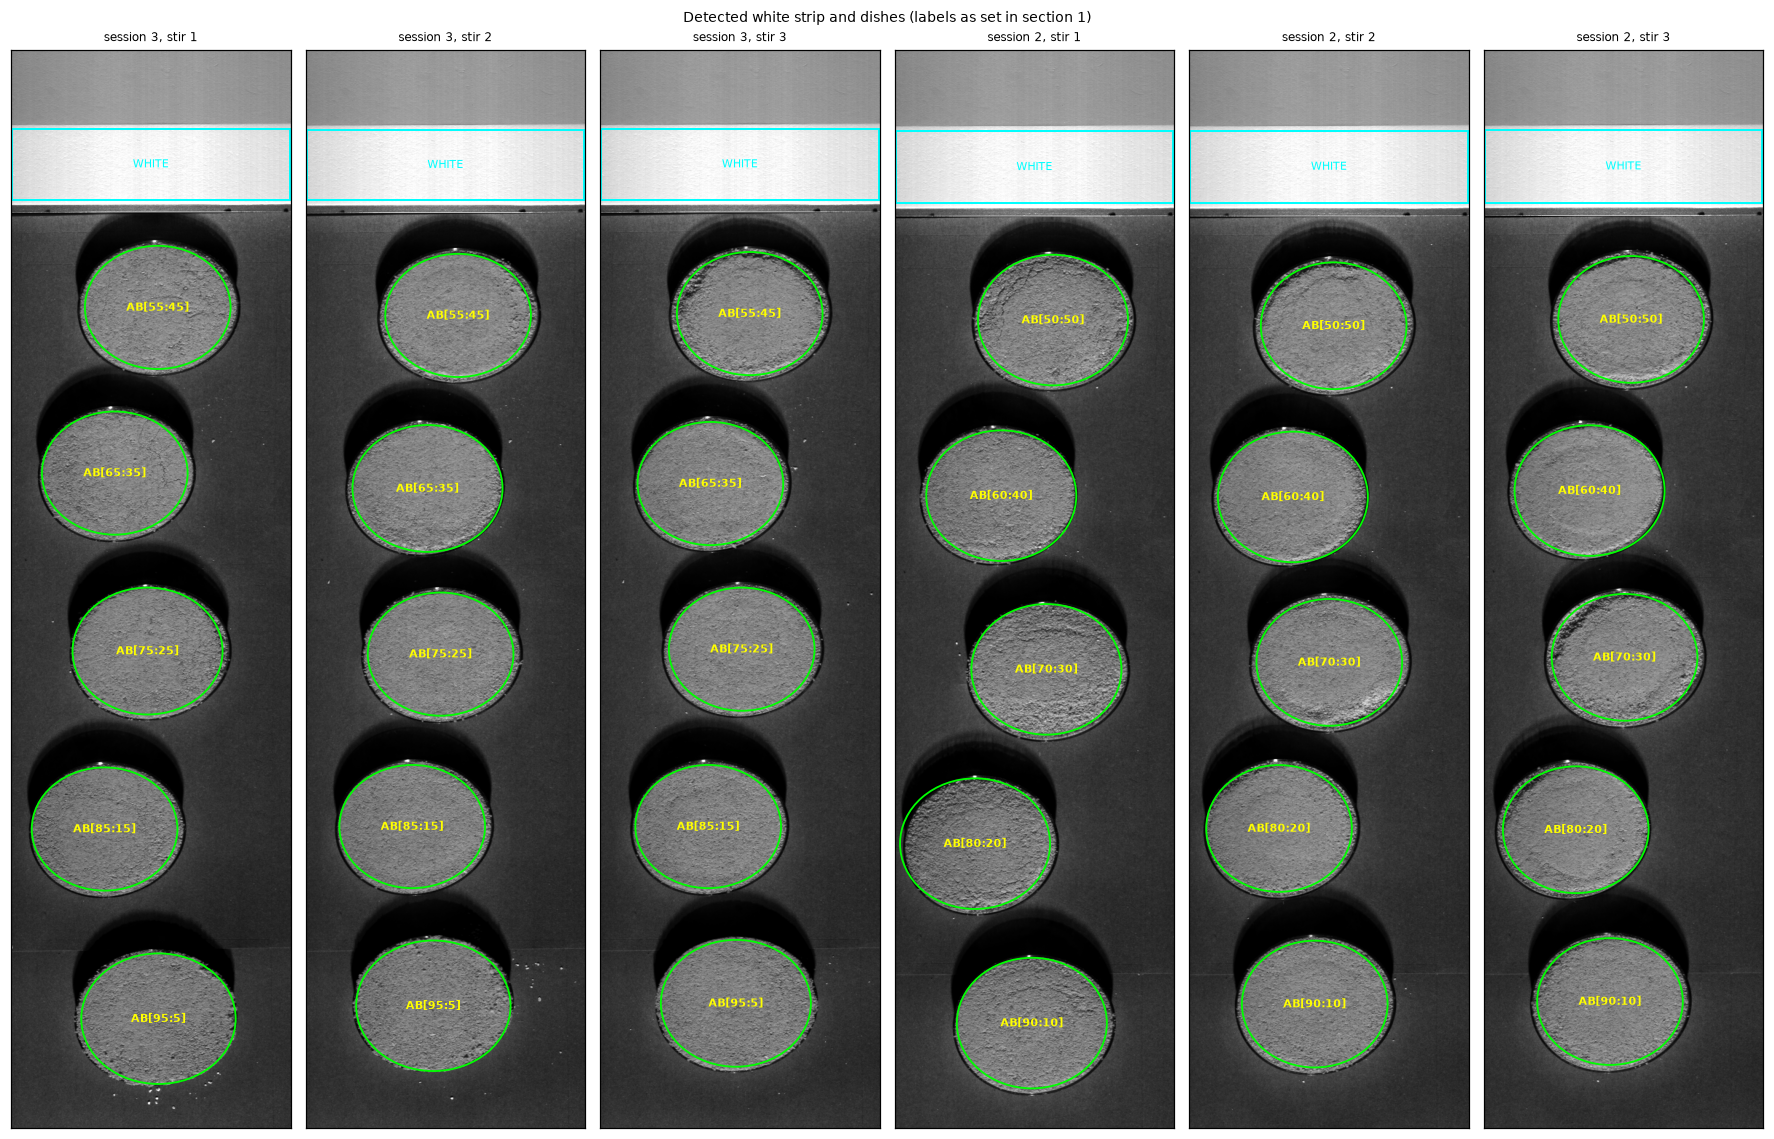

In [6]:
keys = list(CUBES)
fig, axs = plt.subplots(1, len(keys), figsize=(2.7 * len(keys), 10.5))
for ax, key in zip(np.atleast_1d(axs), keys):
    br = CUBES[key].brightness(step=1)
    ax.imshow(br, cmap="gray", aspect="auto", vmin=np.nanpercentile(br, 1), vmax=np.nanpercentile(br, 99.5))
    for lab, s in ALL_ROIS[key].items():
        if s["kind"] == "rect":
            ax.add_patch(Rectangle((s["cx"] - s["ax"], s["cy"] - s["ay"]), 2 * s["ax"], 2 * s["ay"],
                                   fill=False, ec="cyan", lw=1.3))
            ax.text(s["cx"], s["cy"], "WHITE", color="cyan", ha="center", va="center", fontsize=7)
        else:
            ax.add_patch(Ellipse((s["cx"], s["cy"]), 2 * s["ax"], 2 * s["ay"], angle=s.get("angle", 0),
                                 fill=False, ec="lime", lw=1.2))
            ax.text(s["cx"], s["cy"], lab, color="yellow", ha="center", va="center", fontsize=7,
                    fontweight="bold")
    ax.set_title(f"session {INFO[key]['day']}, stir {INFO[key]['capture']}", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Detected white strip and dishes (labels as set in section 1)", fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "rois_overview.png", dpi=110, bbox_inches="tight"); plt.show()

### 5b. Adjusting a shape by hand (optional)

Set `EDIT_BY_HAND = True` in section 1 and list the scans in `REDRAW`. The same window as in the robusta
notebook opens with the automatic shapes loaded: right-drag moves the current shape, `W A S D` resizes,
`n`/`p` switch dish, `ENTER` saves. Needs `opencv-python` (not the headless build).

In [7]:
def screen_size(default=(1600, 900)):
    try:
        import tkinter as tk
        r = tk.Tk(); r.withdraw()
        s = (r.winfo_screenwidth(), r.winfo_screenheight()); r.destroy()
        return s
    except Exception:
        return default

def _u8(img, lo=1.5, hi=99.0):
    a = np.nan_to_num(img.astype(np.float32))
    l, h = np.percentile(a, [lo, hi])
    return np.clip((a-l)/max(h-l, 1e-9)*255, 0, 255).astype(np.uint8)

def ellipse_on_screen(s, sx, sy):
    th = np.deg2rad(s.get("angle", 0.0))
    R = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
    A = R @ np.diag([1/max(s["ax"],1e-6)**2, 1/max(s["ay"],1e-6)**2]) @ R.T
    Si = np.diag([1/max(sx,1e-9), 1/max(sy,1e-9)])
    w, V = np.linalg.eigh(Si @ A @ Si)
    w = np.maximum(w, 1e-12)
    return (float(1/np.sqrt(w[0])), float(1/np.sqrt(w[1]))), float(np.degrees(np.arctan2(V[1,0], V[0,0])))

def draw_rois(cube, key, plate_labels, existing=None):
    SCREEN_W, SCREEN_H = screen_size(); VIEW_W, VIEW_H = int(SCREEN_W*0.86), int(SCREEN_H*0.80)
    base = _u8(cube.brightness(step=1)); H, W = base.shape
    FIT = (VIEW_W/W, VIEW_H/H); ONE = (max(1.0, VIEW_W/W),) * 2
    labels = ["WHITE"] + list(plate_labels)
    shapes = {k: dict(v) for k, v in (existing or {}).items()}
    st = dict(i=0, mode="fit", top=0, move=None, save=False)
    def sxsy(): return FIT if st["mode"] == "fit" else ONE
    def d2o(x, y): sx, sy = sxsy(); return x/sx, (y + st["top"])/sy
    def o2d(x, y): sx, sy = sxsy(); return x*sx, y*sy - st["top"]
    def render():
        sx, sy = sxsy()
        big = cv2.cvtColor(cv2.resize(base, (max(1,int(W*sx)), max(1,int(H*sy))),
                                      interpolation=cv2.INTER_AREA), cv2.COLOR_GRAY2BGR)
        ph = big.shape[0] if st["mode"] == "fit" else min(VIEW_H, big.shape[0])
        st["top"] = int(np.clip(st["top"], 0, max(0, big.shape[0]-ph)))
        view = big[st["top"]:st["top"]+ph].copy(); cur = labels[st["i"]]
        for lab, s in shapes.items():
            col = (0,0,255) if lab == cur else ((0,220,255) if s["kind"] == "rect" else (0,230,0))
            cx, cy = o2d(s["cx"], s["cy"])
            if s["kind"] == "ellipse":
                axes, ang = ellipse_on_screen(s, sx, sy)
                cv2.ellipse(view, (int(cx),int(cy)), (max(1,int(axes[0])), max(1,int(axes[1]))), ang, 0, 360, col, 2)
            else:
                cv2.rectangle(view, (int(cx-s["ax"]*sx),int(cy-s["ay"]*sy)), (int(cx+s["ax"]*sx),int(cy+s["ay"]*sy)), col, 2)
            cv2.putText(view, lab, (int(cx), int(cy)), cv2.FONT_HERSHEY_SIMPLEX, .45, col, 1, cv2.LINE_AA)
        cv2.putText(view, f"[{st['i']+1}/{len(labels)}] {cur}", (8,17), cv2.FONT_HERSHEY_SIMPLEX, .5, (255,255,255), 1)
        cv2.imshow(key, view)
    def on_mouse(ev, x, y, flags, _):
        ox, oy = d2o(x, y); cur = labels[st["i"]]
        if ev == cv2.EVENT_RBUTTONDOWN: st["move"] = (ox, oy)
        elif ev == cv2.EVENT_RBUTTONUP: st["move"] = None
        elif ev == cv2.EVENT_MOUSEMOVE and st["move"] and cur in shapes:
            shapes[cur]["cx"] += ox-st["move"][0]; shapes[cur]["cy"] += oy-st["move"][1]
            st["move"] = (ox, oy); render()
    cv2.namedWindow(key, cv2.WINDOW_NORMAL); cv2.resizeWindow(key, VIEW_W, VIEW_H)
    cv2.setMouseCallback(key, on_mouse); render()
    while True:
        k = cv2.waitKey(20) & 0xFF
        if k == 255: continue
        s = shapes.get(labels[st["i"]])
        if k == 13: st["save"] = True; break
        elif k in (27, ord("q")): break
        elif k == ord("n"): st["i"] = (st["i"]+1) % len(labels)
        elif k == ord("p"): st["i"] = (st["i"]-1) % len(labels)
        elif k == ord("1"): st["mode"] = "fit"; st["top"] = 0
        elif k == ord("2"): st["mode"] = "one"; st["top"] = int(max(0, (s["cy"] if s else 0)*ONE[1] - VIEW_H/2))
        elif k == ord("j"): st["top"] += VIEW_H//2
        elif k == ord("k"): st["top"] -= VIEW_H//2
        elif s:
            if   k == ord("w"): s["cy"] -= 1
            elif k == ord("s"): s["cy"] += 1
            elif k == ord("a"): s["cx"] -= 1
            elif k == ord("d"): s["cx"] += 1
            elif k == ord("W"): s["ay"] += 1
            elif k == ord("S"): s["ay"] = max(2, s["ay"]-1)
            elif k == ord("D"): s["ax"] += 1
            elif k == ord("A"): s["ax"] = max(2, s["ax"]-1)
        render()
    cv2.destroyWindow(key)
    for _ in range(5): cv2.waitKey(1)
    return shapes if st["save"] else None

REDRAW = []          # e.g. ["stir1_SWIR_384_SN3189_9000us_2026-09-04T151627_raw"]
if EDIT_BY_HAND:
    for key in REDRAW:
        res = draw_rois(CUBES[key], key, INFO[key]["plates"], existing=ALL_ROIS.get(key))
        if res:
            ALL_ROIS[key] = res; ROI_FILE.write_text(json.dumps(ALL_ROIS, indent=1)); print("saved", key)
else:
    print("hand editing off -- using the automatic shapes")

hand editing off -- using the automatic shapes


## 6. White reference and dish masks

Same as the robusta notebook. The white reference is the median of the strip rows **per across-track
column**, so the lamp and lens profile across the swath is measured rather than assumed. One addition for
raw counts: a few single detector pixels (one band in one column) respond far below their neighbours. They
are found on the white strip and set to missing, so a patch averages the other columns for that band.

Inside each dish shape: pixels below 55 % of the dish median (rim, shadow) and above the 99.7th percentile,
dilated by 1 px (glare), are removed, and the shape is eroded by `ERODE_PX`.

In [8]:
def shape_mask(shape, H, W):
    m = np.zeros((H, W), np.uint8)
    if shape["kind"] == "poly":
        cv2.fillPoly(m, [np.array([[int(round(a)), int(round(b))] for a, b in shape["pts"]], np.int32)], 1)
        return m.astype(bool)
    cx, cy = int(round(shape["cx"])), int(round(shape["cy"]))
    ax, ay = int(round(shape["ax"])), int(round(shape["ay"]))
    if shape["kind"] == "ellipse":
        cv2.ellipse(m, (cx, cy), (max(ax,1), max(ay,1)), shape.get("angle", 0), 0, 360, 1, -1)
    else:
        cv2.rectangle(m, (cx-ax, cy-ay), (cx+ax, cy+ay), 1, -1)
    return m.astype(bool)


def clean_mask(mask, bright, kind="ellipse", erode=ERODE_PX, dark_frac=0.55, spec_q=99.7):
    m = mask.astype(np.uint8)
    e = 0 if kind == "poly" else erode
    if e > 0:
        m = cv2.erode(m, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*e+1, 2*e+1)))
    m = m.astype(bool)
    if m.sum() < 30: return m
    m &= bright > dark_frac * np.nanmedian(bright[m])
    if m.sum() > 50:
        hi = np.nanpercentile(bright[m], spec_q)
        m &= ~cv2.dilate((bright > hi).astype(np.uint8), np.ones((3,3), np.uint8)).astype(bool)
    return m


def build_white(cube, shape, bad_frac=0.5, pix_tol=0.5):
    r0, r1 = int(shape["cy"] - shape["ay"]), int(shape["cy"] + shape["ay"])
    c0, c1 = int(shape["cx"] - shape["ax"]), int(shape["cx"] + shape["ax"])
    r0, c0 = max(0, r0), max(0, c0)
    r1, c1 = min(cube.shape[0], r1), min(cube.shape[1], c1)
    S = cube.shape[1]
    W = np.full((S, cube.wl.size), np.nan)
    W[c0:c1] = np.nanmedian(cube.region(r0, r1, c0, c1), axis=0)
    # whole columns far below the rest are repaired from their neighbours (as for robusta)
    ref = np.nanmedian(W[c0:c1], axis=0)
    lvl = np.nanmedian(W / np.maximum(ref, 1e-9), axis=1)
    bad = ~np.isfinite(lvl) | (lvl < bad_frac)
    good = np.where(~bad)[0]
    if bad.any() and good.size > 2:
        for jb in range(W.shape[1]):
            W[bad, jb] = np.interp(np.where(bad)[0], good, W[good, jb])
    # single detector pixels (column, band) that disagree with their column neighbours
    local = ndimage.median_filter(np.nan_to_num(W), size=(9, 1), mode="nearest")
    badpix = ~np.isfinite(W) | (W <= 0) | (np.abs(W / np.maximum(local, 1e-9) - 1) > pix_tol)
    return W, badpix, (r0, r1, c0, c1), int(bad.sum()), (c1 - c0) / S


WHITE, BADPIX, MASKS = {}, {}, {}
for key in ALL_ROIS:
    cube = CUBES[key]; H, Wd = cube.shape[0], cube.shape[1]
    Wc, bp, wbox, nbad, cov = build_white(cube, ALL_ROIS[key]["WHITE"])
    WHITE[key], BADPIX[key] = Wc, bp
    print(f"{key[:45]}: white rows {wbox[0]}-{wbox[1]}, spans {cov*100:.0f}% of the swath, "
          f"{nbad} columns repaired, {bp.sum()} single bad detector pixels")
    br = cube.brightness(step=1)
    mk = {}
    for lab in INFO[key]["plates"]:
        sh = ALL_ROIS[key][lab]
        raw = shape_mask(sh, H, Wd)
        cl = clean_mask(raw, br, kind=sh["kind"])
        mk[lab] = dict(raw=raw, mask=cl, n=int(cl.sum()), keep=float(cl.sum()/max(raw.sum(), 1)))
        print(f"    {lab:10s} {cl.sum():7d} px ({mk[lab]['keep']*100:.0f}% of the shape)")
    MASKS[key] = mk

/tmp/ipykernel_17215/4129208707.py:36: RuntimeWarning: All-NaN slice encountered
  W[c0:c1] = np.nanmedian(cube.region(r0, r1, c0, c1), axis=0)
/tmp/ipykernel_17215/4129208707.py:39: RuntimeWarning: All-NaN slice encountered
  lvl = np.nanmedian(W / np.maximum(ref, 1e-9), axis=1)


batch2stir1_SWIR_384_SN3189_9000us_2026-09-08: white rows 128-242, spans 99% of the swath, 3 columns repaired, 9 single bad detector pixels
    AB[55:45]    28451 px (90% of the shape)
    AB[65:35]    28435 px (90% of the shape)
    AB[75:25]    30240 px (90% of the shape)
    AB[85:15]    28359 px (90% of the shape)
    AB[95:5]     31912 px (90% of the shape)


batch2stir2_SWIR_384_SN3189_9000us_2026-09-08: white rows 129-243, spans 99% of the swath, 3 columns repaired, 9 single bad detector pixels
    AB[55:45]    28544 px (90% of the shape)
    AB[65:35]    30426 px (91% of the shape)
    AB[75:25]    28472 px (90% of the shape)
    AB[85:15]    28500 px (90% of the shape)
    AB[95:5]     32007 px (90% of the shape)


batch2stir3_SWIR_384_SN3189_9000us_2026-09-08: white rows 128-242, spans 99% of the swath, 3 columns repaired, 9 single bad detector pixels
    AB[55:45]    27828 px (88% of the shape)
    AB[65:35]    28583 px (90% of the shape)
    AB[75:25]    28475 px (90% of the shape)
    AB[85:15]    28417 px (90% of the shape)
    AB[95:5]     30306 px (90% of the shape)


stir1_SWIR_384_SN3189_9000us_2026-09-04T15162: white rows 127-241, spans 99% of the swath, 3 columns repaired, 9 single bad detector pixels
    AB[50:50]    29552 px (88% of the shape)
    AB[60:40]    30301 px (90% of the shape)
    AB[70:30]    29664 px (88% of the shape)
    AB[80:20]    28762 px (86% of the shape)
    AB[90:10]    29920 px (89% of the shape)


stir2_SWIR_384_SN3189_9000us_2026-09-04T15272: white rows 127-240, spans 99% of the swath, 3 columns repaired, 9 single bad detector pixels
    AB[50:50]    28238 px (89% of the shape)
    AB[60:40]    30442 px (91% of the shape)
    AB[70:30]    28599 px (90% of the shape)
    AB[80:20]    28283 px (89% of the shape)
    AB[90:10]    28529 px (90% of the shape)


stir3_SWIR_384_SN3189_9000us_2026-09-04T15381: white rows 126-240, spans 99% of the swath, 3 columns repaired, 9 single bad detector pixels
    AB[50:50]    28567 px (90% of the shape)
    AB[60:40]    30460 px (91% of the shape)
    AB[70:30]    27568 px (87% of the shape)
    AB[80:20]    28189 px (89% of the shape)
    AB[90:10]    28362 px (90% of the shape)


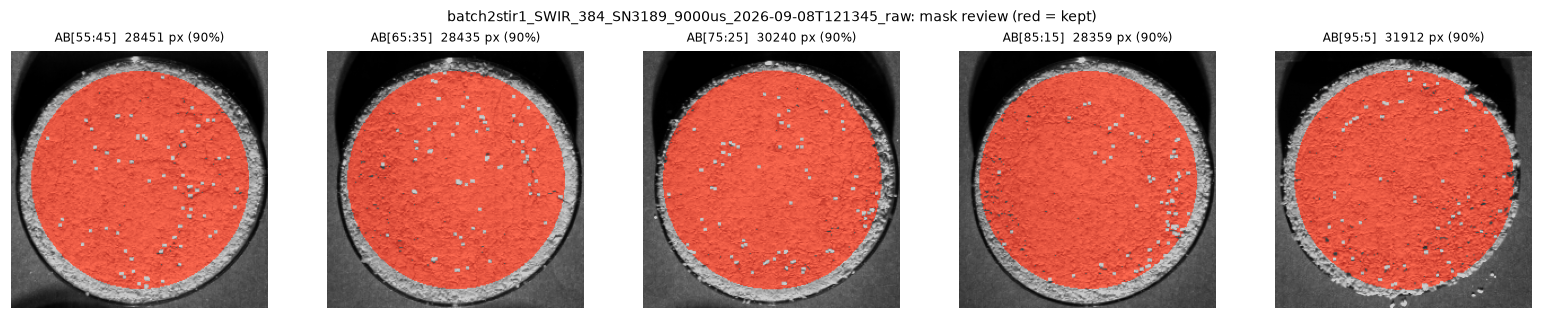

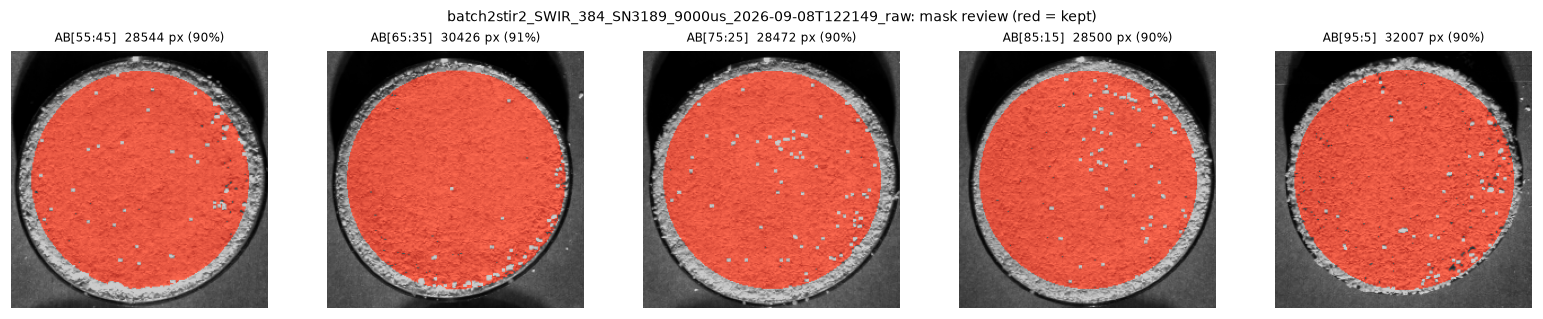

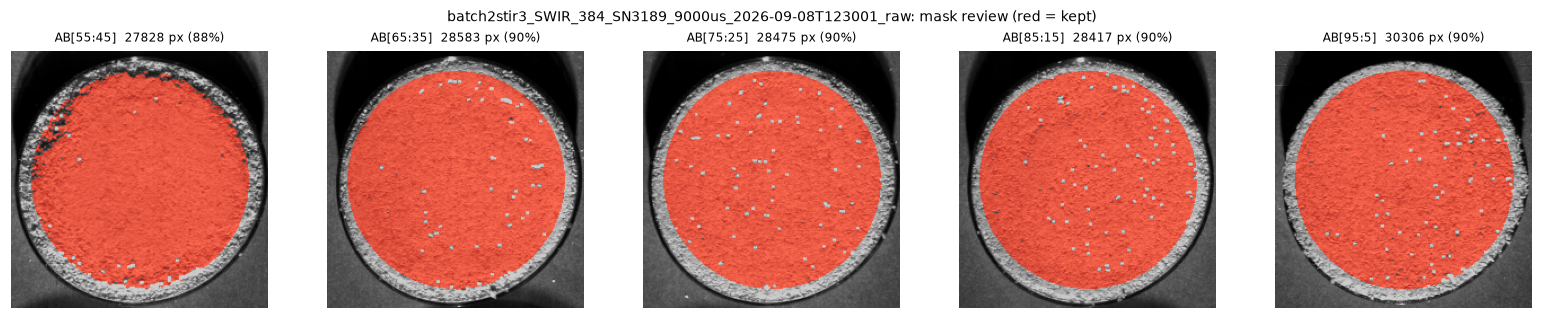

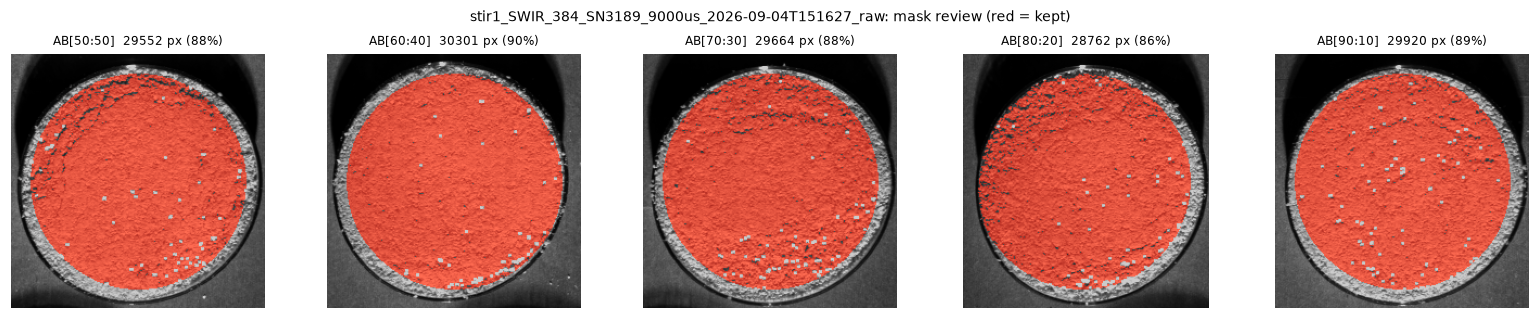

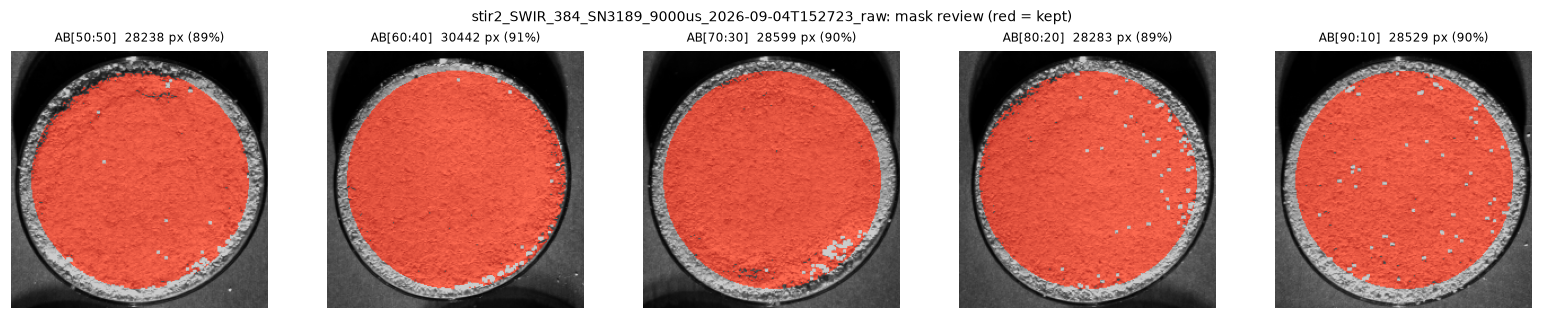

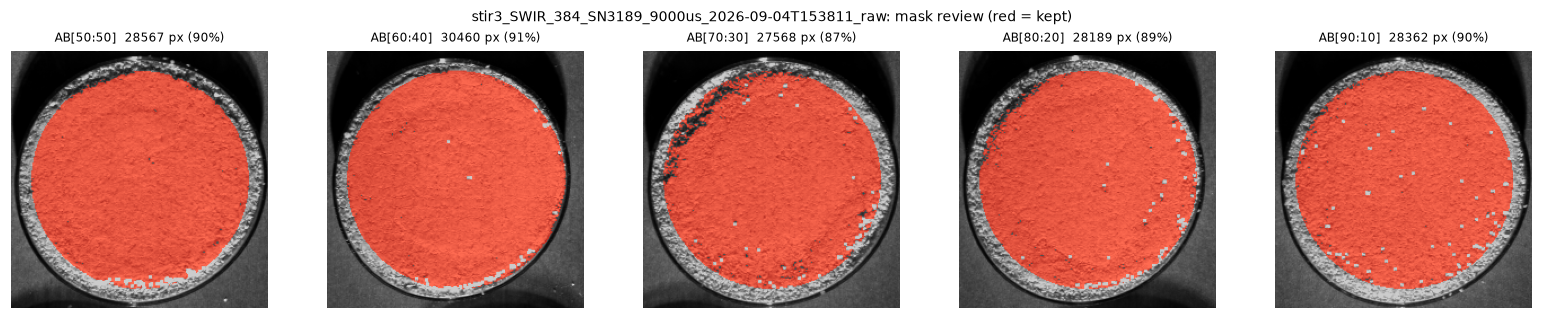

In [9]:
def review(key, cols=5):
    br = CUBES[key].brightness(step=1)
    items = list(MASKS[key].items())
    rows = int(np.ceil(len(items)/cols))
    fig, axs = plt.subplots(rows, cols, figsize=(2.9*cols, 2.9*rows), squeeze=False)
    for ax in axs.ravel(): ax.axis("off")
    for jx, (lab, d) in enumerate(items):
        r, c = divmod(jx, cols); ax = axs[r][c]
        ys, xs = np.where(d["raw"])
        p = 14
        r0, r1 = max(0, ys.min()-p), min(br.shape[0], ys.max()+p)
        c0, c1 = max(0, xs.min()-p), min(br.shape[1], xs.max()+p)
        sub = np.nan_to_num(br[r0:r1, c0:c1])
        lo, hi = np.nanpercentile(sub, [2, 98])
        g = np.clip((sub-lo)/max(hi-lo, 1e-9), 0, 1)
        rgb = np.dstack([g, g, g]); mm = d["mask"][r0:r1, c0:c1]
        rgb[...,0] = np.where(mm, np.clip(g*.5+.5, 0, 1), g*.8)
        rgb[...,1] = np.where(mm, g*.42, g*.8)
        rgb[...,2] = np.where(mm, g*.32, g*.8)
        ax.imshow(np.clip(rgb, 0, 1)); ax.axis("off")
        ax.set_title(f"{lab}  {d['n']} px ({d['keep']*100:.0f}%)", fontsize=8)
    fig.suptitle(f"{key}: mask review (red = kept)", fontsize=9)
    plt.tight_layout(); plt.savefig(OUT / f"{key}_masks.png", dpi=125, bbox_inches="tight"); plt.show()

for key in MASKS: review(key)

## 7. Reflectance and patch sampling

    R(row, col, band) = [raw(row, col, band) − background(col, band)] / white(col, band) × R_certified(band)

where `white` is the background-subtracted white strip from section 6. Applied inside each dish mask only.
Patches: 12 × 12 px on a non-overlapping grid, kept if ≥ 92 % of their pixels are in the mask, at most
150 per dish (random subsample, seed 0), each averaged into one spectrum.

In [10]:
def plate_reflectance(key, lab):
    cube = CUBES[key]; d = MASKS[key][lab]
    ys, xs = np.where(d["mask"])
    if ys.size == 0: return None
    r0, r1, c0, c1 = ys.min(), ys.max()+1, xs.min(), xs.max()+1
    L = cube.region(r0, r1, c0, c1)
    W = WHITE[key][c0:c1, :][None, :, :]
    R = L / np.maximum(W, 1e-9) * R_WHITE[None, None, :]
    R[np.broadcast_to(BADPIX[key][None, c0:c1, :], R.shape)] = np.nan
    R[(R < -0.05) | (R > 1.6)] = np.nan
    return R, d["mask"][r0:r1, c0:c1], (int(r0), int(c0))


def sample_patches(R, m, patch=PATCH, stride=STRIDE, min_valid=MIN_VALID, max_n=MAX_PER_PLATE, rng=RNG):
    H, Wd, B = R.shape
    specs, pos = [], []
    for i in range(0, H-patch+1, stride):
        for jx in range(0, Wd-patch+1, stride):
            sm = m[i:i+patch, jx:jx+patch]
            if sm.mean() < min_valid: continue
            s = np.nanmean(R[i:i+patch, jx:jx+patch, :][sm], axis=0)
            if np.all(np.isfinite(s)):
                specs.append(s); pos.append((i+patch//2, jx+patch//2, int(sm.sum())))
    if not specs: return np.empty((0, R.shape[2])), []
    if max_n and len(specs) > max_n:
        keep = np.sort(rng.choice(len(specs), max_n, replace=False))
        specs = [specs[k] for k in keep]; pos = [pos[k] for k in keep]
    return np.array(specs), pos


X, rows = [], []
for key in MASKS:
    for lab in INFO[key]["plates"]:
        res = plate_reflectance(key, lab)
        if res is None: continue
        R, m, (r0, c0) = res
        specs, pos = sample_patches(R, m)
        if specs.shape[0] == 0:
            print(f"{key} {lab}: no valid patches"); continue
        X.append(specs)
        info = parse_label(lab)
        for si, (pr, pc, npx) in enumerate(pos):
            rows.append(dict(sample_id=f"{key}|{lab}|{si:04d}", scan=key, day=INFO[key]["day"],
                             capture=INFO[key]["capture"], label=lab, **info,
                             group=f"{key}|{lab}", plate=f"day{INFO[key]['day']}|{lab}",
                             patch_row=r0+pr, patch_col=c0+pc, n_pixels=npx))
        print(f"{key[:40]:40s} {lab:10s} {int(m.sum()):6d} px -> {specs.shape[0]:4d} patches")

X = np.vstack(X); META = pd.DataFrame(rows)
print(f"\n{X.shape[0]} patches x {X.shape[1]} bands from {META['scan'].nunique()} scans, "
      f"{META['group'].nunique()} dishes")
print(META.groupby(["day", "capture"]).size().rename("patches").to_string())
print(f"patch = {PATCH}x{PATCH} px ~ {PATCH*MM_PER_PX:.1f} x {PATCH*MM_PER_PX:.1f} mm")

batch2stir1_SWIR_384_SN3189_9000us_2026- AB[55:45]   28451 px ->  150 patches


batch2stir1_SWIR_384_SN3189_9000us_2026- AB[65:35]   28435 px ->  150 patches
batch2stir1_SWIR_384_SN3189_9000us_2026- AB[75:25]   30240 px ->  150 patches


batch2stir1_SWIR_384_SN3189_9000us_2026- AB[85:15]   28359 px ->  150 patches
batch2stir1_SWIR_384_SN3189_9000us_2026- AB[95:5]    31912 px ->  150 patches


batch2stir2_SWIR_384_SN3189_9000us_2026- AB[55:45]   28544 px ->  150 patches
batch2stir2_SWIR_384_SN3189_9000us_2026- AB[65:35]   30426 px ->  150 patches


batch2stir2_SWIR_384_SN3189_9000us_2026- AB[75:25]   28472 px ->  150 patches
batch2stir2_SWIR_384_SN3189_9000us_2026- AB[85:15]   28500 px ->  150 patches


batch2stir2_SWIR_384_SN3189_9000us_2026- AB[95:5]    32007 px ->  150 patches
batch2stir3_SWIR_384_SN3189_9000us_2026- AB[55:45]   27828 px ->  150 patches
batch2stir3_SWIR_384_SN3189_9000us_2026- AB[65:35]   28583 px ->  150 patches


... (3 outputs left out)

stir1_SWIR_384_SN3189_9000us_2026-09-04T AB[90:10]   29920 px ->  150 patches
stir2_SWIR_384_SN3189_9000us_2026-09-04T AB[50:50]   28238 px ->  150 patches
stir2_SWIR_384_SN3189_9000us_2026-09-04T AB[60:40]   30442 px ->  150 patches


stir2_SWIR_384_SN3189_9000us_2026-09-04T AB[70:30]   28599 px ->  150 patches
stir2_SWIR_384_SN3189_9000us_2026-09-04T AB[80:20]   28283 px ->  150 patches
stir2_SWIR_384_SN3189_9000us_2026-09-04T AB[90:10]   28529 px ->  150 patches


stir3_SWIR_384_SN3189_9000us_2026-09-04T AB[50:50]   28567 px ->  150 patches
stir3_SWIR_384_SN3189_9000us_2026-09-04T AB[60:40]   30460 px ->  150 patches
stir3_SWIR_384_SN3189_9000us_2026-09-04T AB[70:30]   27568 px ->  150 patches


stir3_SWIR_384_SN3189_9000us_2026-09-04T AB[80:20]   28189 px ->  150 patches
stir3_SWIR_384_SN3189_9000us_2026-09-04T AB[90:10]   28362 px ->  150 patches

4500 patches x 288 bands from 6 scans, 30 dishes
day  capture
2    1          750
     2          750
     3          750
3    1          750
     2          750
     3          750
patch = 12x12 px ~ 8.8 x 8.8 mm


## 8. Roles and splits

The same columns as the robusta CSVs. All ten arabica blends are `calibration` (5–50 % chicory).
`fold_level` is leave-one-concentration-out, `fold_capture` is leave-one-stir-out (repeatability, not
validation), `split_holdout` holds out 30 % for quick tests. There is no random split, deliberately:
patches from one dish are near-copies of each other.

In [11]:
CAL_MAX_CHICORY, HOLDOUT_LEVEL, N_PLATE_FOLDS = 50.0, 30.0, 5

def add_splits(meta):
    meta = meta.copy()
    def assign_role(r):
        if r["unknown"]: return "unknown"
        if r["species"] == "chicory": return "extrapolation_check"
        return "calibration" if r["chicory_pct"] <= CAL_MAX_CHICORY else "extrapolation_check"
    meta["role"] = meta.apply(assign_role, axis=1)
    cal = meta["role"] == "calibration"
    lmap = {v: i for i, v in enumerate(sorted(meta.loc[cal, "chicory_pct"].unique()))}
    gmap = {g: i % N_PLATE_FOLDS for i, g in enumerate(sorted(meta.loc[cal, "group"].unique()))}
    for col, val in [("fold_level", meta.loc[cal, "chicory_pct"].map(lmap)),
                     ("fold_plate", meta.loc[cal, "group"].map(gmap)),
                     ("fold_capture", meta.loc[cal, "capture"])]:
        meta[col] = pd.NA; meta.loc[cal, col] = val; meta[col] = meta[col].astype("Int64")
    meta["split_holdout"] = np.where(~cal, "excluded",
                            np.where(meta["chicory_pct"] == HOLDOUT_LEVEL, "test", "train"))
    return meta

META = add_splits(META)
print(META.groupby(["day", "label", "role"]).agg(chicory=("chicory_pct", "first"),
      dishes=("group", "nunique"), patches=("sample_id", "size")).to_string())

                           chicory  dishes  patches
day label     role                                 
2   AB[50:50] calibration     50.0       3      450
    AB[60:40] calibration     40.0       3      450
    AB[70:30] calibration     30.0       3      450
    AB[80:20] calibration     20.0       3      450
    AB[90:10] calibration     10.0       3      450
3   AB[55:45] calibration     45.0       3      450
    AB[65:35] calibration     35.0       3      450
    AB[75:25] calibration     25.0       3      450
    AB[85:15] calibration     15.0       3      450
    AB[95:5]  calibration      5.0       3      450


## 9. The CSVs

- `training_samples.csv`: the new arabica patches only (sessions 2 and 3), same columns as
  `samples_out/training_samples.csv` with `arabica_pct` in place of `robusta_pct`.
- `arabica_chicory_all_sessions.csv`: the above plus the session-1 dishes from `samples_out/`: **AB100**
  (pure arabica, 0 % chicory, `calibration`) and **CH100** (pure chicory, `extrapolation_check`). This is the
  arabica counterpart of the robusta set: 0 % from session 1 and 5–50 % from sessions 2 and 3, 11 levels.
  The `source` column says which extraction each row came from.

In [12]:
wl_cols = [str(w) for w in WL_R]
META_COLS = ["sample_id", "scan", "day", "capture", "label", "plate", "species",
             "arabica_pct", "chicory_pct", "unknown", "role", "group",
             "fold_level", "fold_plate", "fold_capture", "split_holdout",
             "patch_row", "patch_col", "n_pixels"]

df = pd.concat([META[META_COLS].reset_index(drop=True),
                pd.DataFrame(np.round(X, 6), columns=wl_cols)], axis=1)
df.to_csv(OUT / "training_samples.csv", index=False)
pd.DataFrame({"band": np.arange(1, WL.size+1), "wavelength_exact_nm": np.round(WL, 4),
              "wavelength_rounded_nm": WL_R, "white_certified": np.round(R_WHITE, 5),
              "beyond_certificate": OUTSIDE}).to_csv(OUT / "wavelengths.csv", index=False)
np.savez_compressed(OUT / "training_samples.npz", X=X, wl=WL, wl_rounded=WL_R,
                    meta=META[META_COLS].astype(str).to_records(index=False))

# session 1 anchors from the robusta extraction (same camera, same settings, 1 Sep)
s1 = pd.read_csv(S1_CSV)
s1 = s1[s1.label.isin(["AB100", "CH100"])].copy()
s1["arabica_pct"] = np.where(s1.label == "AB100", 100.0, 0.0)
s1["species"] = np.where(s1.label == "AB100", "arabica", "chicory")
s1 = s1.drop(columns=["robusta_pct"])
s1["source"] = "samples_out (1 Sep, HySpex radiance)"
new = df.copy(); new["source"] = "arabica_out (raw counts)"
allm = pd.concat([s1[META_COLS + ["source"]], new[META_COLS + ["source"]]], ignore_index=True)
allm = add_splits(allm.drop(columns=["role", "fold_level", "fold_plate", "fold_capture", "split_holdout"]))
allx = pd.concat([s1[wl_cols], new[wl_cols]], ignore_index=True)
ALL = pd.concat([allm[META_COLS + ["source"]], allx], axis=1)
ALL.to_csv(OUT / "arabica_chicory_all_sessions.csv", index=False)

print(f"training_samples.csv:             {df.shape[0]:5d} rows x {df.shape[1]} columns")
print(f"arabica_chicory_all_sessions.csv: {ALL.shape[0]:5d} rows "
      f"({(ALL.role=='calibration').sum()} calibration, {(ALL.role=='extrapolation_check').sum()} CH100)")
print("\ncalibration levels (% chicory):", sorted(ALL.loc[ALL.role == "calibration", "chicory_pct"].unique()))
print(ALL[ALL.role == "calibration"].groupby("day").agg(levels=("chicory_pct", lambda v: sorted(v.unique())),
      dishes=("group", "nunique"), patches=("sample_id", "size")).to_string())

training_samples.csv:              4500 rows x 307 columns
arabica_chicory_all_sessions.csv:  5386 rows (4950 calibration, 436 CH100)

calibration levels (% chicory): [np.float64(0.0), np.float64(5.0), np.float64(10.0), np.float64(15.0), np.float64(20.0), np.float64(25.0), np.float64(30.0), np.float64(35.0), np.float64(40.0), np.float64(45.0), np.float64(50.0)]
                             levels  dishes  patches
day                                                 
1                             [0.0]       3      450
2    [10.0, 20.0, 30.0, 40.0, 50.0]      15     2250
3     [5.0, 15.0, 25.0, 35.0, 45.0]      15     2250


## 10. First look at the spectra, and a check of the dish order

Left: mean spectrum of each arabica blend (both sessions, all stirs). Right: spread of the patches within
one dish.

**Dish-order check.** The labels in section 1 assume the dish nearest the white strip has the most chicory,
as in the robusta sessions. Each dish's mean spectrum (absorbance with its own offset removed, 1000–2450 nm,
the same preprocessing as the robusta model) is placed on the line from pure arabica (AB100) to pure chicory
(CH100), both from session 1. 0 = looks like pure arabica, 1 = looks like pure chicory. This score uses no
blend labels at all. If the labels are in the right order, the score should rise with the labelled chicory
in every scan. The absolute values are not calibrated (session differences shift them); only the order
matters here.

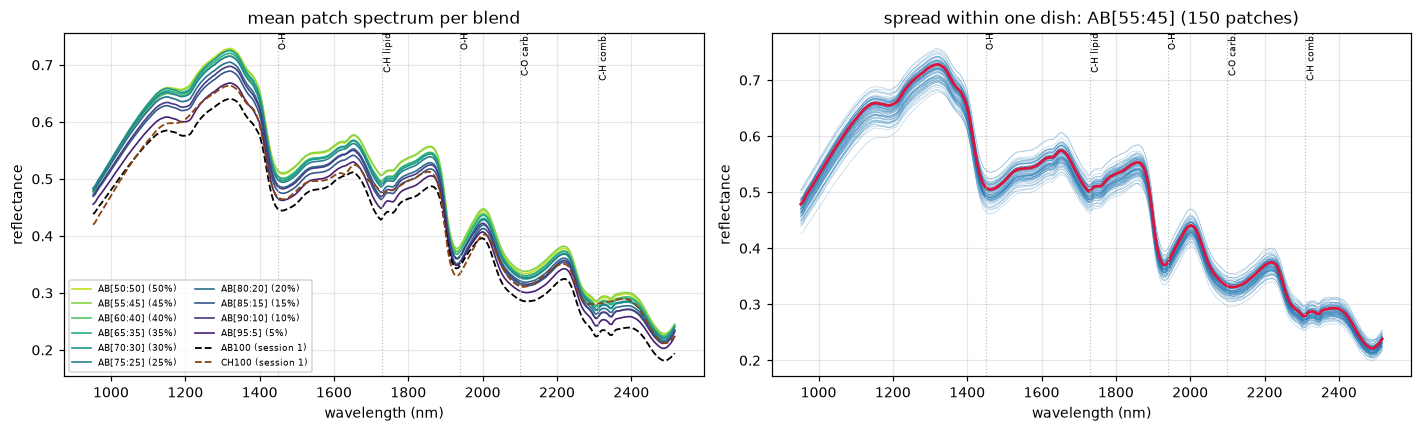

mean within-dish spread:        0.0165 reflectance units
spread between the blend levels: 0.0137


In [13]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
cmap = plt.get_cmap("viridis")
for lab, g in META.groupby("label"):
    pct = g["chicory_pct"].iloc[0]
    axs[0].plot(WL, X[g.index].mean(0), lw=1.1, color=cmap(pct / 55), label=f"{lab} ({pct:.0f}%)")
ab = ALL[ALL.label == "AB100"][wl_cols].to_numpy().mean(0)
ch = ALL[ALL.label == "CH100"][wl_cols].to_numpy().mean(0)
axs[0].plot(WL, ab, "k--", lw=1.2, label="AB100 (session 1)")
axs[0].plot(WL, ch, ls="--", color="saddlebrown", lw=1.2, label="CH100 (session 1)")
axs[0].set_title("mean patch spectrum per blend"); axs[0].legend(fontsize=6, ncol=2)
big = META.groupby("group").size().idxmax(); sel = (META["group"] == big).values
for s in X[sel][:80]: axs[1].plot(WL, s, lw=.4, alpha=.35, color="tab:blue")
axs[1].plot(WL, X[sel].mean(0), lw=1.8, color="crimson")
axs[1].set_title(f"spread within one dish: {big.split('|')[-1]} ({sel.sum()} patches)")
for ax in axs:
    for nm, t in [(1450,"O-H"), (1730,"C-H lipid"), (1940,"O-H"), (2100,"C-O carb."), (2310,"C-H comb.")]:
        ax.axvline(nm, color="0.75", lw=.8, ls=":")
        ax.text(nm, ax.get_ylim()[1], t, fontsize=6, rotation=90, va="top")
    ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("reflectance"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "samples_overview.png", dpi=130, bbox_inches="tight"); plt.show()

sd_within = float(np.mean([X[(META["group"] == g).values].std(0).mean() for g in META["group"].unique()]))
sd_between = float(np.mean(np.std([X[(META["label"] == l).values].mean(0) for l in META.label.unique()], axis=0)))
print(f"mean within-dish spread:        {sd_within:.4f} reflectance units")
print(f"spread between the blend levels: {sd_between:.4f}")

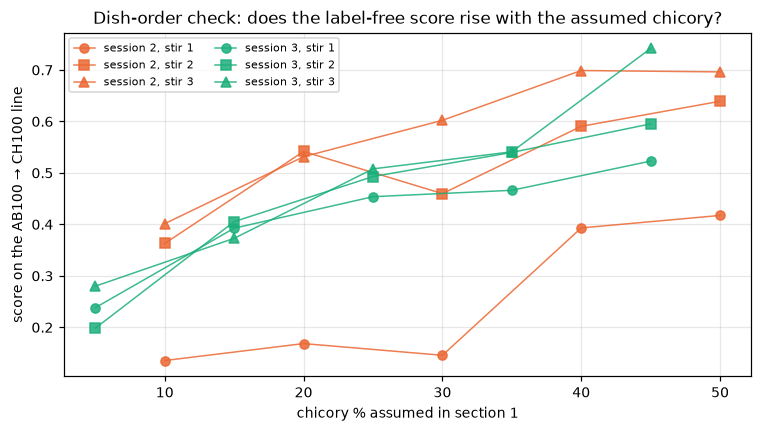

 session  stir  spearman                                            order_by_score
       3     1       1.0  AB[55:45] > AB[65:35] > AB[75:25] > AB[85:15] > AB[95:5]
       3     2       1.0  AB[55:45] > AB[65:35] > AB[75:25] > AB[85:15] > AB[95:5]
       3     3       1.0  AB[55:45] > AB[65:35] > AB[75:25] > AB[85:15] > AB[95:5]
       2     1       0.9 AB[50:50] > AB[60:40] > AB[80:20] > AB[70:30] > AB[90:10]
       2     2       0.9 AB[50:50] > AB[60:40] > AB[80:20] > AB[70:30] > AB[90:10]
       2     3       0.9 AB[60:40] > AB[50:50] > AB[70:30] > AB[80:20] > AB[90:10]

mean rank correlation: 0.95 (+1 = score order exactly matches the assumed labels, -1 = exactly reversed)


In [14]:
band = (WL >= 1000) & (WL <= 2450)
def prep(R):
    Z = np.log10(1.0 / np.clip(np.asarray(R, float), 1e-3, None))[..., band]
    return Z - Z.mean(-1, keepdims=True)
z_ab, z_ch = prep(ab), prep(ch); d = z_ch - z_ab
dish = (META.assign(i=np.arange(len(META))).groupby(["scan", "day", "capture", "label"])
        .agg(chicory_pct=("chicory_pct", "first"), idx=("i", list)).reset_index())
dish["score"] = [float((prep(X[ix].mean(0)) - z_ab) @ d / (d @ d)) for ix in dish["idx"]]
dish["position"] = [INFO[k]["plates"].index(l) + 1 for k, l in zip(dish.scan, dish.label)]

from scipy.stats import spearmanr
fig, ax = plt.subplots(figsize=(7, 4))
for (day, cap), g in dish.groupby(["day", "capture"]):
    g = g.sort_values("chicory_pct")
    ax.plot(g.chicory_pct, g.score, marker="os^"[cap - 1], lw=1, color={2: "#eb6834", 3: "#1baf7a"}[day],
            alpha=.85, label=f"session {day}, stir {cap}")
ax.set_xlabel("chicory % assumed in section 1"); ax.set_ylabel("score on the AB100 → CH100 line")
ax.set_title("Dish-order check: does the label-free score rise with the assumed chicory?")
ax.legend(fontsize=7, ncol=2); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "dish_order_check.png", dpi=130, bbox_inches="tight"); plt.show()

rows = []
for (scan, day, cap), g in dish.groupby(["scan", "day", "capture"]):
    rho = spearmanr(g.chicory_pct, g.score).statistic
    rows.append(dict(session=day, stir=cap, spearman=round(float(rho), 2),
                     order_by_score=" > ".join(g.sort_values("score", ascending=False).label)))
print(pd.DataFrame(rows).to_string(index=False))
print(f"\nmean rank correlation: {np.mean([r['spearman'] for r in rows]):.2f} "
      "(+1 = score order exactly matches the assumed labels, -1 = exactly reversed)")
dish.drop(columns="idx").to_csv(OUT / "dish_order_check.csv", index=False)

## 11. What this gives you, and what comes next

- `arabica_out/training_samples.csv`: one row per 12 × 12 px patch from the 30 new dishes (2 sessions ×
  3 stirs × 5 blends), reflectance at 288 bands, ready for the same modelling as robusta.
- `arabica_out/arabica_chicory_all_sessions.csv`: the same plus AB100 and CH100 from session 1, giving the
  arabica set the same shape as the robusta one (0 % + 5–50 % chicory, 11 levels, 3 sessions).
- Figures: `check_raw_vs_radiance.png`, `rois_overview.png`, one `*_masks.png` per scan,
  `samples_overview.png`, `dish_order_check.png`.

**Next step:** point the nested leave-one-session-out notebook (`robusta_chicory_nested_loso.ipynb`) at
`arabica_chicory_all_sessions.csv` (species `arabica` / `arabica_chicory` instead of `robusta` /
`robusta_chicory`) to get the arabica result in the same way as the robusta one.

**Same caveat as robusta:** session 1 holds only the 0 % dish, session 2 the 10/20/30/40/50 % blends and
session 3 the 5/15/25/35/45 % blends, so a session difference can look like a chicory difference. The
leave-one-session-out test is what measures that.